In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# Storage health

Can each scope's drives hold a continuous recording, and are they healthy? This notebook measures the
sustained write speed of the experiment SSD and the OS SD card, how long single writes take, whether a
15.7 MB/s recording would keep up, and whether everything written reads back intact.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: [`scripts/debug/storage_health_statistics.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/debug/storage_health_statistics.py),
`create_exp()` then `start_acq_blocking()`. No acquisition may run at the same time. About 60–70 min per scope.

The SSD gets up to 20 files of 9.45 GB (one real 10-minute split each), written in 64 MiB chunks with an
fdatasync after every chunk, so each timing is the drive's and not the page cache's. Writing stops before the
drive is 85% full. Every chunk is then read back and checked against its CRC. The SD card gets one 1 GB file.
SMART is read before and after, with the drive idle; fstrim runs at the end; all test files are deleted.

In [2]:
import glob, json, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rich, yaml
from explorer.legacy import ExpExplorer

DATA = "/Users/byatharth/data/debugging/2026_11_13_storage_health_data"   # set to your own runs
OUT = "results"                                        # the fleet table is written here
REQ = 15.7                                             # MB/s a continuous recording needs
SCOPES = [f"M{i}" for i in range(1, 9)]
COLORS = dict(zip(SCOPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                           "#e87ba4", "#008300", "#6250d6", "#e34948"]))
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`. One row per run.

In [3]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA, extended_parse=True)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))))

runs = pd.DataFrame([{"scope": d["metadata"]["name"].split("__")[0], "eid": eid,
                      "started": d["metadata"]["created"], "dir": exps.get_parent_dir(eid)}
                     for eid, d in exps.data.items()]).sort_values(["scope", "started"])
runs["run"] = runs.groupby("scope").cumcount() + 1
rows = res.groupby(["eid", "stream"]).size().unstack(fill_value=0)
runs = runs.join(rows, on="eid").set_index(["scope", "run"])
runs.drop(columns="dir")

<Experiments :: 8  datasets [extended_parse]>
  |- eid: 1747b88b61
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: e7bd42937f
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: eb24ad3b69
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: 4c4a04c905
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: fe5113873e
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: a08363733a
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: a513054d7f
  	|- m-stream: tandh
  	|- m-stream: devices
  	|- m-stream: smart
  	|- m-stream: files
  	|- m-stream: verify
  |- eid: 2b7362

,,eid,started,devices,files,smart,tandh,verify
scope,run,,,,,,,
M1,1,eb24ad3b69,2026-11-13 13:47:47.836920,2,21,2,14,21
M2,1,2b73626532,2026-11-13 13:48:52.723347,2,21,2,15,21
M3,1,1747b88b61,2026-11-13 13:50:05.417656,2,21,2,11,21
M4,1,fe5113873e,2026-11-13 13:50:19.910108,2,21,2,14,21
M5,1,4c4a04c905,2026-11-13 13:53:27.671033,2,21,2,14,21
M6,1,a513054d7f,2026-11-13 13:53:39.882207,2,21,2,15,21
M7,1,e7bd42937f,2026-11-13 13:53:55.227346,2,21,2,15,21
M8,1,a08363733a,2026-11-13 13:54:09.823871,2,21,2,14,21


In [4]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:10s} {len(g):5d} rows   {', '.join(cols)}")

M1__YB__2026_11_13__13hh_47mm__storage_health__eb24ad3b69
    REPORT.md
    experiment.yaml
    kernel.log
    logs.yaml
    sessions.yaml
    storage_health.json
    telemetry.csv
    analysis/
    converted/
    postprocess/
    protocols/
    raw/
    scripts/

devices       16 rows   bridge, disk, fstype, kind, model, mountpoint, role, size_gb, transport, used_pct
files        168 rows   disk, chunk_ms_max, chunk_ms_p50, chunk_ms_p99, chunks_over_1s, chunks_over_5s, fill_pct_after, gb, mean_mb_s, n, seconds
smart         16 rows   disk, crc_errors, health, lbas_written, pct_used, pending, phase, power_on_h, realloc, temp_c
tandh        112 rows   humidity, temp
verify       168 rows   disk, n, chunks_bad, chunks_ok, read_mb_s


Each run folder also holds the files the analysis uses:

- `telemetry.csv`: one row per second per drive, with `phase` (`write_<disk>_NNN`, `verify_<disk>_NNN`, ...)
  and `write_mb_s`, `read_mb_s` from `/proc/diskstats`.
- `storage_health.json`: drive identity, SMART before and after, per-file results and fstrim.
- `raw/<disk>/smart_before.txt`, `smart_after.txt`: the full smartctl output.
- `raw/<disk>/chunks.csv`: every chunk's write and read time and CRC (runs from script `bba7aed` on).
- `kernel.log`: kernel messages during the run.

In [5]:
def find(d, pattern):
    hit = sorted(glob.glob(os.path.join(d, "**", pattern), recursive=True))
    return hit[0] if hit else None

def load(row):
    t = pd.read_csv(f"{row.dir}/telemetry.csv")
    t = t[t.disk == "sda"].reset_index(drop=True)
    t["dt"] = t.elapsed_s.diff().fillna(1.0)               # rows are ~1 s apart, not exactly
    t["mb"] = t.write_mb_s * t.dt
    edge = (t.phase != t.phase.shift()) | (t.phase != t.phase.shift(-1))
    w = t[t.phase.str.startswith("write_sda") & ~edge].reset_index(drop=True)  # drop file switches
    w["gb"] = w.mb.cumsum() / 1000
    w["minutes"] = (w.elapsed_s - w.elapsed_s.iloc[0]) / 60
    return w

W = {k: load(r) for k, r in runs.iterrows()}
J = {k: json.load(open(f"{r.dir}/storage_health.json")) for k, r in runs.iterrows()}
dev = lambda k, disk: next(x for x in J[k]["devices"] if x["device"]["name"] == disk)
pd.Series({k: len(w) for k, w in W.items()}, name="seconds of SSD writing").to_frame().T

,M1,M2,M3,M4,M5,M6,M7,M8
,1,1,1,1,1,1,1,1
seconds of SSD writing,2491,3304,2020,2583,3104,3239,3330,3150


## Write speed as the drive fills

Most SSDs first write into a fast cache (flash used one bit per cell), then slow down once it is full. A flat
line at the start that drops to a lower one shows where the cache ran out, and the lower line is the speed a
long recording actually gets. Repeated swings between high and very low speed mean the drive pauses to empty
its cache while still writing.

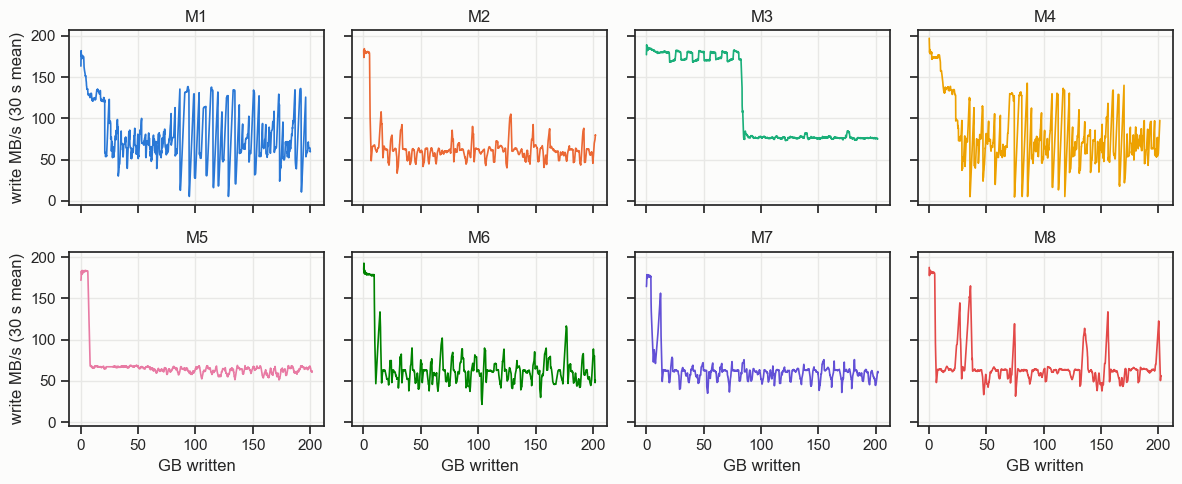

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SCOPES):
    for (sc, run), w in W.items():
        if sc == s:
            ax.plot(w.gb, w.write_mb_s.rolling(30, min_periods=1).mean(),
                    color=COLORS[s], alpha=1 / run)
    ax.set_title(s)
for ax in axes[1]:
    ax.set_xlabel("GB written")
for ax in axes[:, 0]:
    ax.set_ylabel("write MB/s (30 s mean)")
fig.tight_layout()

In [7]:
def cache(w, drop=0.5, win=60):
    """GB written before the 60 s mean first falls below half the opening speed, and the speed after it."""
    mb, dt, gb = w.mb.to_numpy(), w.dt.to_numpy(), w.gb.to_numpy()
    roll = pd.Series(mb).rolling(win).sum() / pd.Series(dt).rolling(win).sum()
    below = np.flatnonzero(roll.to_numpy() < drop * mb[:30].sum() / dt[:30].sum())
    if not len(below):
        return np.nan, mb.sum() / dt.sum()
    cut = below[0] - win // 2
    return gb[cut], mb[cut:].sum() / dt[cut:].sum()

cache_tab = pd.DataFrame([cache(w) for w in W.values()], index=runs.index,
                         columns=["cache_gb", "post_cache_mb_s"])
cache_tab.round(1)

,,cache_gb,post_cache_mb_s
scope,run,,
M1,1,22.1,65.1
M2,1,5.7,60.0
M3,1,84.4,76.6
M4,1,23.3,63.9
M5,1,7.4,63.5
M6,1,10.7,60.1
M7,1,13.4,58.5
M8,1,5.5,63.1


## How fast the drive writes, second by second

The distribution of the per-second write speed over the whole test, on a log axis. A curve that rises steeply in
one place means a steady drive. A curve with a step far to the left means the drive spends that fraction of
its time nearly stalled.

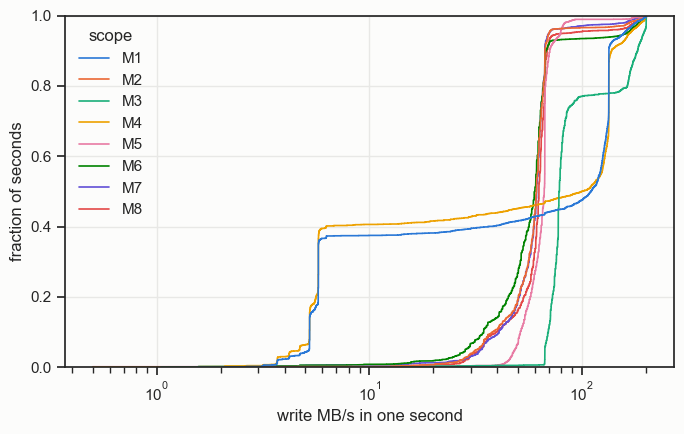

In [8]:
d = pd.concat([pd.DataFrame({"scope": k[0], "write_mb_s": w.write_mb_s.clip(lower=0.5)})
               for k, w in W.items()])
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.ecdfplot(d, x="write_mb_s", hue="scope", palette=COLORS, log_scale=True, ax=ax)
ax.set_xlabel("write MB/s in one second")
ax.set_ylabel("fraction of seconds")
fig.tight_layout()

## Would a recording keep up?

A recording produces 15.7 MB every second. Feed that into the speed the drive actually delivered, second by
second, and count how much would be left waiting. Zero means the drive kept up. The seconds in which the test
switches from one file to the next are left out, since that pause is the test's and not the drive's. Tall or
long peaks are data a recording would have to hold in memory until the drive caught up.

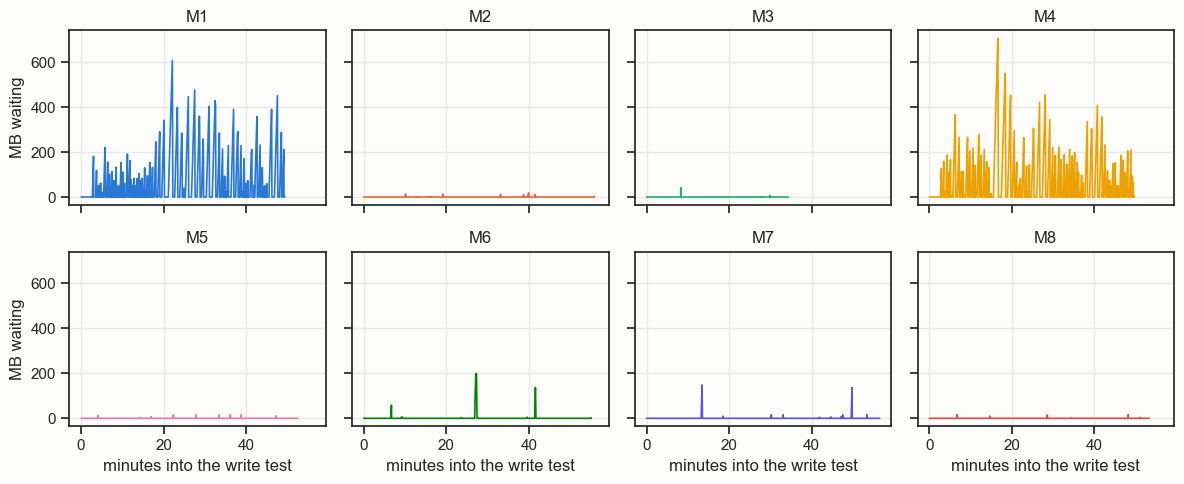

In [9]:
def queue(mb, dt, rate=REQ):
    q, out = 0.0, []
    for m, s in zip(mb, dt):
        q = max(0.0, q + rate * s - m)
        out.append(q)
    return np.array(out)

fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
behind = {}
for ax, s in zip(axes.flat, SCOPES):
    for (sc, run), w in W.items():
        if sc == s:
            q = queue(w.mb.to_numpy(), w.dt.to_numpy())
            behind[(sc, run)] = q.max()
            ax.plot(w.minutes, q, color=COLORS[s], alpha=1 / run)
    ax.set_title(s)
for ax in axes[1]:
    ax.set_xlabel("minutes into the write test")
for ax in axes[:, 0]:
    ax.set_ylabel("MB waiting")
fig.tight_layout()

## Read-back

Every chunk is read back from the drive, not from memory, and checked against its CRC. One point per file; the
box shows the median and interquartile range for each scope. The USB bridge, not the flash, usually sets the
ceiling here, so drives behind the same bridge should line up.

,files,chunks_bad
scope,,
M1,20,0.0
M2,20,0.0
M3,20,0.0
M4,20,0.0
M5,20,0.0
M6,20,0.0
M7,20,0.0
M8,20,0.0


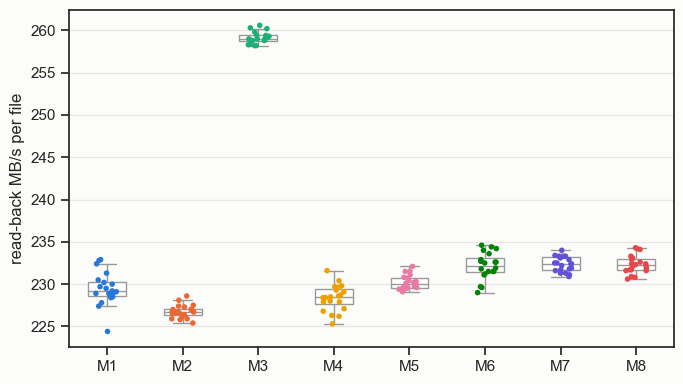

In [10]:
rb = (res.query("stream == 'verify' and disk == 'sda'")
      .assign(scope=lambda d: d.eid.map(runs.reset_index().set_index("eid").scope)))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(rb, x="scope", y="read_mb_s", order=SCOPES, color="white", width=0.5,
            showfliers=False, ax=ax)
sns.stripplot(rb, x="scope", y="read_mb_s", order=SCOPES, hue="scope", palette=COLORS,
              size=4, jitter=0.15, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("read-back MB/s per file")
fig.tight_layout()
rb.groupby("scope").agg(files=("read_mb_s", "size"), chunks_bad=("chunks_bad", "sum"))

## Results

In [11]:
def ident(k, r):
    sd, ssd = dev(k, "mmcblk0"), dev(k, "sda")
    smart = open(find(r.dir, "sda/smart_before.txt")).read()
    fw = re.search(r"Firmware Version:\s*(\S+)", smart)
    trim = J[k].get("fstrim", {}).get("sda", "")
    trim = trim.get("supported") if isinstance(trim, dict) else "trimmed" in trim
    b, a = ssd["smart_before"], ssd["smart_after"]
    f = ssd["workload"]["files"]
    return {"model": ssd["identity"].get("model"), "firmware": fw.group(1) if fw else None,
            "bridge": ssd["identity"].get("bridge"), "trim": trim,
            "slowest_file_mb_s": min(x["mean_mb_s"] for x in f),
            "worst_chunk_s": max(x["chunk_ms_max"] for x in f) / 1000,
            "read_mb_s": np.median([x["read_mb_s"] for x in f]),
            "crc_bad": sum(x["chunks_bad"] for x in f),
            "smart": b.get("health"),
            "smart_worse": any(a.get(c, 0) > b.get(c, 0) for c in
                               ("realloc", "pending", "media_errors", "crc_errors")),
            "kernel_errors": len(ssd.get("kernel_storage_errors", [])),
            "sd_write_mb_s": sd["workload"]["files"][0]["mean_mb_s"],
            "sd_read_mb_s": sd["workload"]["files"][0]["read_mb_s"]}

fleet = pd.DataFrame([ident(k, r) for k, r in runs.iterrows()], index=runs.index)
fleet = (runs[["eid"]].join(fleet).join(cache_tab)
         .assign(behind_mb_max=[behind[k] for k in runs.index]))

In [12]:
fail = ((fleet.crc_bad > 0) | (fleet.smart != "PASSED") | fleet.smart_worse
        | (fleet.kernel_errors > 0) | (fleet.post_cache_mb_s < 3 * REQ))
warn = fleet.behind_mb_max > 2 * REQ                       # more than 2 s of video waiting
fleet["verdict"] = np.select([fail, warn], ["FAIL", "WARN"], "PASS")

os.makedirs(OUT, exist_ok=True)
fleet.to_csv(f"{OUT}/storage_health.csv")
for k, row in fleet.iterrows():                           # one copy next to each run's data
    with open(os.path.join(exps.get_analysis_dir(row.eid), "storage_health.yaml"), "w") as f:
        yaml.safe_dump({c: (v.item() if hasattr(v, "item") else v) for c, v in row.items()}, f)
fleet.round(2)

,,eid,model,firmware,bridge,trim,slowest_file_mb_s,worst_chunk_s,read_mb_s,crc_bad,smart,smart_worse,kernel_errors,sd_write_mb_s,sd_read_mb_s,cache_gb,post_cache_mb_s,behind_mb_max,verdict
scope,run,,,,,,,,,,,,,,,,,,
M1,1,eb24ad3b69,NTech MX600 SSD,V1027A0,174c:55aa,False,55.2,14.07,229.15,0,PASSED,False,0,13.5,41.9,22.09,65.06,607.96,WARN
M2,1,2b73626532,NTech MX600 SSD,Y0407A2,174c:55aa,False,52.2,4.91,226.70,0,PASSED,False,0,13.1,40.6,5.71,60.05,18.22,PASS
M3,1,1747b88b61,Elements SE SSD,331030WD,1058:266e,True,71.3,3.95,259.00,0,PASSED,False,0,9.7,40.7,84.36,76.59,41.47,WARN
M4,1,fe5113873e,NTech MX600 SSD,V1027A0,174c:55aa,False,48.1,15.27,228.45,0,PASSED,False,0,16.4,40.7,23.26,63.95,706.33,WARN
M5,1,4c4a04c905,Samsung SSD 870 QVO 1TB,SVQ02B6Q,174c:55aa,False,56.2,1.55,230.05,0,PASSED,False,0,12.9,40.7,7.43,63.51,15.86,PASS
M6,1,a513054d7f,NTech MX600 SSD,Y0407A2,174c:55aa,False,51.7,14.76,232.20,0,PASSED,False,0,12.3,42.0,10.68,60.12,198.11,WARN
M7,1,e7bd42937f,NTech MX600 SSD,Y0407A2,174c:55aa,False,51.7,10.42,232.40,0,PASSED,False,0,17.8,40.5,13.43,58.52,148.28,WARN
M8,1,a08363733a,NTech MX600 SSD,Y0407A2,174c:55aa,False,47.3,3.92,232.25,0,PASSED,False,0,17.3,40.7,5.50,63.07,15.83,PASS


## Acceptance

Per scope, for the experiment SSD:

| Criterion | Level |
|---|---|
| Any chunk reads back wrong (CRC) | FAIL |
| SMART not PASSED, or reallocated, pending, media or link-CRC errors rose during the run | FAIL |
| A kernel storage error or reset on the drive during the run | FAIL |
| Speed after the cache runs out below 3 × 15.7 = 47 MB/s | FAIL |
| A 15.7 MB/s recording would have more than 2 s of video (31 MB) waiting | WARN |

WARN is informational: this test bypasses the page cache, which absorbs part of a real recording's waiting.
TRIM and the SD card figures are reported but not judged: most USB bridges do not pass TRIM, and the SD card
holds the OS, not recordings.

## Persistent records

This calibration writes 0 records to the scope.